# Animated stickman Visualizer

### Features

- visualize in HTML or plotlib
- can save to gif
- more than one motion per subplot can be visualized
- independent camera orientation can be set for different subplots

In [1]:
import numpy as np

from hmp_utils.motion.body_models_constants import SmplConstants, H36MConstants
from hmp_utils.motion.mocap_processor import MocapLoader
from hmp_utils.motion.kinematics import ForwardKinematics
from hmp_utils.visualize.stickman_animation import pose_animation, CameraOrientation, AnimationMode

For convenience, an example mocap sequence from AMASS is loaded. But in general, any keypoint positional data can be visualized.

In [2]:
filepath = "./example_mocaps/walking_poses.npz"
animation_framerate = 30
max_len_frames = 200

# -- load mocap --
mocap_loader = MocapLoader(body_model_type=SmplConstants.BODY_MODEL_TYPE, keypoint_ids_to_load=SmplConstants.KEYPOINTS, target_framerate=animation_framerate)
motion = mocap_loader.load_mocap(filepath)
assert motion is not None

# -- compute joint positions --
kine = ForwardKinematics(SmplConstants.OFFSETS, SmplConstants.PARENTS)
kine.set_body_model_type(SmplConstants.BODY_MODEL_TYPE)
keypoints_positions = kine.compute_fk(motion.rots, apply_root_rotation=True)
keypoints_positions = keypoints_positions[:max_len_frames]

## Animation Modes

### Plotlib and Save to gif

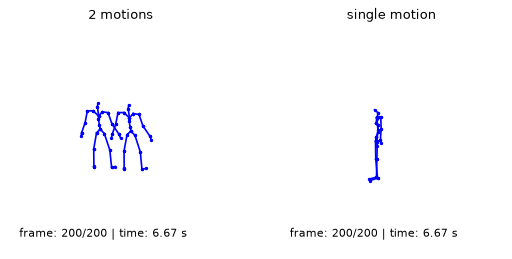

In [3]:
example_offset = np.array([0.5, 0, 0])
motions_list = [keypoints_positions, keypoints_positions + example_offset, keypoints_positions]
subplot_ids = [0, 0, 1]
subplot_titles = ["2 motions", "single motion"]
camera_orientations = [CameraOrientation(100, 20), CameraOrientation(0, 0)]
pose_animation(
    motions_list,
    SmplConstants.PARENTS,
    animation_framerate,
    subplot_ids=subplot_ids,
    camera_orientations=camera_orientations,
    subplot_titles=subplot_titles,
    animation_mode=AnimationMode.PLOTLIB,
    gif_savepath="./test_outputs/test_animation.gif",
)

### Visualize on notebook with HTML

**Note**: `ffmpeg` is needed for `html5` modes.

If not installed run:
```
sudo apt-get install ffmpeg
```

#### HTML

In [4]:
motions_list = [keypoints_positions, keypoints_positions]
subplot_ids = [0, 1]
subplot_colors = ["r", "m"]
subplot_titles = ["mocap 1", "mocap 2"]
camera_orientations = [CameraOrientation(100, 20), CameraOrientation(0, 0), CameraOrientation(0, 0)]
pose_animation(
    motions_list,
    SmplConstants.PARENTS,
    animation_framerate,
    subplot_ids=subplot_ids,
    camera_orientations=camera_orientations,
    subplot_titles=subplot_titles,
    subplot_colors=subplot_colors,
    animation_mode=AnimationMode.HTML,
)

#### HTML 5

In [5]:
import numpy as np

example_offset = np.array([0.5, 0, 0])
motions_list = [keypoints_positions, keypoints_positions + example_offset, keypoints_positions]
subplot_ids = [0, 0, 1]
subplot_titles = ["2 motions", "single motion"]
camera_orientations = [CameraOrientation(100, 20), CameraOrientation(0, 0)]
pose_animation(
    motions_list,
    SmplConstants.PARENTS,
    animation_framerate,
    subplot_ids=subplot_ids,
    camera_orientations=camera_orientations,
    subplot_titles=subplot_titles,
    fig_opts={"dpi": 90},
    animation_mode=AnimationMode.HTML5,
)

## Examples with Human3.6m

### From source file in 3d coordinates:

In [6]:
import numpy as np

filepath = "./example_mocaps/human_3d_sample.npy"  # [25,32,3]
keypoints_positions = np.load(filepath)  # [frame,joint,3] 3d positions

motions_list = [keypoints_positions]
subplot_ids = [0]
subplot_colors = ["b"]
subplot_titles = ["Human36m"]
camera_orientations = CameraOrientation(-90, 90)
pose_animation(
    motions_list,
    parents=H36MConstants.PARENTS,
    animation_framerate=25,
    subplot_ids=subplot_ids,
    camera_orientations=camera_orientations,
    subplot_titles=subplot_titles,
    subplot_colors=subplot_colors,
    animation_mode=AnimationMode.HTML,
    fig_opts={"dpi": 100},
)

### From source file in angle-axis notation:

In [7]:
import numpy as np

filepath = "./example_mocaps/human_ang_sample.npy"  # [25,33,3]
motion = np.load(filepath)  # [frame,joint,3] angle-axis notation
assert motion is not None

# -- remove global position --
motion = np.array(motion[:, 1:, :])

# -- compute joint positions --
kine = ForwardKinematics(H36MConstants.OFFSETS, H36MConstants.PARENTS, offsets_are_relative=True, left_mul=True)
keypoints_positions = kine.compute_fk(motion) / 1000

motions_list = [keypoints_positions]
subplot_ids = [0]
subplot_colors = ["b"]
subplot_titles = ["Human36m"]
camera_orientations = CameraOrientation(-90, 120)
pose_animation(
    motions_list,
    parents=H36MConstants.PARENTS,
    animation_framerate=25,
    subplot_ids=subplot_ids,
    camera_orientations=camera_orientations,
    subplot_titles=subplot_titles,
    subplot_colors=subplot_colors,
    animation_mode=AnimationMode.HTML,
    fig_opts={"dpi": 120},
)